# 8.2. 文本预处理

将文本作为字符串加载到内存中。

将字符串拆分为词元（如单词和字符）。

建立一个词表，将拆分的词元映射到数字索引。

将文本转换为数字索引序列，方便模型操作。

In [4]:
import collections
import re
from d2l import torch as d2l
DATA_DIR = '/home/beichen/jiaxinl/data/timemachine.txt'

In [5]:
#@save
d2l.DATA_HUB['time_machine'] = (d2l.DATA_URL + 'timemachine.txt',
                                '090b5e7e70c295757f55df93cb0a180b9691891a')

# 读取文本、清洗文本
def read_time_machine():  #@save
    """将时间机器数据集加载到文本行的列表中"""
    path = DATA_DIR
    with open(path, 'r') as f:
        lines = f.readlines() # f.readlines()：读取文件的所有行，返回一个列表。
    return [re.sub('[^A-Za-z]+', ' ', line).strip().lower() for line in lines]
# 如果是中文的话怎么弄
lines = read_time_machine()
print(f'# 文本总行数: {len(lines)}')
print(lines[0])
print(lines[10])

# 文本总行数: 3221
the time machine by h g wells
twinkled and his usually pale face was flushed and animated the


- `re.sub()`：使用正则表达式替换文本
- `[^A-Za-z]+`:匹配一个或多个非英文字母
- `.strip()`:去掉字符串首尾的空格
- `.lower()`:全部转换为小写

## 8.2.2. 词元化

In [6]:
def tokenize(lines, token='word'):  #@save
    """将文本行拆分为单词或字符词元"""
    if token == 'word': # 单词
        return [line.split() for line in lines]
    elif token == 'char': # 字符
        return [list(line) for line in lines]
    else:
        print('错误：未知词元类型：' + token)
# 两种拆分方式，模型可以选择不同的文本处理粒度
# 单词级：["time", "machine"]，字符级：["t", "i", "m", "e", ...]
tokens = tokenize(lines)
for i in range(11):
    print(tokens[i])

['the', 'time', 'machine', 'by', 'h', 'g', 'wells']
[]
[]
[]
[]
['i']
[]
[]
['the', 'time', 'traveller', 'for', 'so', 'it', 'will', 'be', 'convenient', 'to', 'speak', 'of', 'him']
['was', 'expounding', 'a', 'recondite', 'matter', 'to', 'us', 'his', 'grey', 'eyes', 'shone', 'and']
['twinkled', 'and', 'his', 'usually', 'pale', 'face', 'was', 'flushed', 'and', 'animated', 'the']


- `line.split()`:按照空白字符拆分字符串
```python
        line = "the time machine"
        line.split()
        结果：["the", "time", "machine"]
```

- `list(line)`:会把字符串拆成一个个字符
```python
        list("time")
        结果：["t", "i", "m", "e"]
```

## 8.2.3. 词表

词元的类型是字符串，而模型需要的输入是数字，因此这种类型不方便模型使用。 现在，让我们构建一个字典，通常也叫做词表（vocabulary）， 用来将字符串类型的词元映射到从0
开始的数字索引中。

- `tokens`；传入要建立词表的文本
- `reserved_tokens`：指定必须保留的特殊词元

In [7]:
class Vocab:  #@save
    """文本词表"""
    def __init__(self, tokens=None, min_freq=0, reserved_tokens=None):
        if tokens is None:
            tokens = []  # 如果创建词表时没有传入tokens,就使用空列表
        if reserved_tokens is None:
            reserved_tokens = []
        # 按出现频率排序
        counter = count_corpus(tokens)# 统计每个词元出现多少次。
        # 按照出现频率从高到低排序。
        self._token_freqs = sorted(
            counter.items(), # 取出词元和频率组成的键值对。
            key=lambda x: x[1],# 按照每个键值对的第二个元素排序，也就是频率
            reverse=True # 从大到小排序。
            )
        # 未知词元的索引为0
        self.idx_to_token = ['<unk>'] + reserved_tokens
        self.token_to_idx = {
            token: idx
            for idx, token in enumerate(self.idx_to_token)}
        for token, freq in self._token_freqs:
            if freq < min_freq:
                break
            if token not in self.token_to_idx:
                self.idx_to_token.append(token)
                self.token_to_idx[token] = len(self.idx_to_token) - 1

    def __len__(self):
        return len(self.idx_to_token)

    # 把词元转换成数字
    def __getitem__(self, tokens):
        if not isinstance(tokens, (list, tuple)):
            return self.token_to_idx.get(tokens, self.unk)
        return [self.__getitem__(token) for token in tokens]
    # 把数字转换回词元
    def to_tokens(self, indices):
        if not isinstance(indices, (list, tuple)):
            return self.idx_to_token[indices]
        return [self.idx_to_token[index] for index in indices]

    @property
    def unk(self):  # 未知词元的索引为0
        return 0

    @property
    def token_freqs(self):
        return self._token_freqs

def count_corpus(tokens):  #@save
    """统计词元的频率"""
    # 这里的tokens是1D列表或2D列表
    if len(tokens) == 0 or isinstance(tokens[0], list):
        # 将词元列表展平成一个列表
        tokens = [token for line in tokens for token in line]
    return collections.Counter(tokens)

- `isinstance(变量, 类型)`:判断变量是不是指定的类型。

- `counter = count_corpus(tokens)`:
结果：
```python
{
    "the": 2,
    "time": 2,
    "machine": 1,
    "by": 1
}
```

In [8]:
vocab = Vocab(tokens)
print(list(vocab.token_to_idx.items())[:10])

[('<unk>', 0), ('the', 1), ('i', 2), ('and', 3), ('of', 4), ('a', 5), ('to', 6), ('was', 7), ('in', 8), ('that', 9)]


In [9]:
# 分别取出第 0 行和第 10 行文本，然后看看它们转换成数字编号之后是什么样子。
for i in [0, 10]:
    print('文本:', tokens[i])
    print('索引:', vocab[tokens[i]]) # 调用def __getitem__(self, tokens):

文本: ['the', 'time', 'machine', 'by', 'h', 'g', 'wells']
索引: [1, 19, 50, 40, 2183, 2184, 400]
文本: ['twinkled', 'and', 'his', 'usually', 'pale', 'face', 'was', 'flushed', 'and', 'animated', 'the']
索引: [2186, 3, 25, 1044, 362, 113, 7, 1421, 3, 1045, 1]


In [10]:
def load_corpus_time_machine(max_tokens=-1):  #@save
    """返回时光机器数据集的词元索引列表和词表"""
    lines = read_time_machine()
    tokens = tokenize(lines, 'char')
    vocab = Vocab(tokens) # 创建一个词表对象。
    # 因为时光机器数据集中的每个文本行不一定是一个句子或一个段落，
    # 所以将所有文本行展平到一个列表中
    corpus = [vocab[token] for line in tokens for token in line]
    if max_tokens > 0: # 限制数据长度
        corpus = corpus[:max_tokens]
    return corpus, vocab

corpus, vocab = load_corpus_time_machine()
len(corpus), len(vocab)
#corpus:整本书转换得到的数字序列
#vocab;字符和数字之间的映射表

(170580, 28)

# 8.3. 语言模型和数据集

主要在讲
- 理解语言模型要学习什么：根据前面的词元，预测下一个词元。
- 准备训练数据：把一长串文本数字序列，切成一批批输入 X 和标签 Y。

In [11]:
import random
import torch
from d2l import torch as d2l
tokens = d2l.tokenize(read_time_machine())
# 因为每个文本行不一定是一个句子或一个段落，因此我们把所有文本行拼接到一起
corpus = [token for line in tokens for token in line]
vocab = Vocab(corpus) # new一个对象
vocab.token_freqs[:10]

[('the', 2261),
 ('i', 1267),
 ('and', 1245),
 ('of', 1155),
 ('a', 816),
 ('to', 695),
 ('was', 552),
 ('in', 541),
 ('that', 443),
 ('my', 440)]

- `corpus = [token for line in tokens for token in line]`等价于
```python
    corpus = []
    for line in tokens:
        for token in line
            corpus.append(token)
```
- 本质是把二维列表展平成一维列表

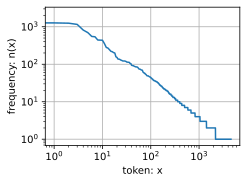

In [12]:
freqs = [freq for token , freq in vocab.token_freqs]
d2l.plot(freqs, xlabel='token: x', ylabel='frequency: n(x)',
         xscale='log', yscale='log')
# xscale='log'：横坐标使用对数刻度。
# yscale='log'：纵坐标也使用对数刻度

In [13]:
print(len(freqs))    

4579


猜一下上面代码的意思：
首先，freqs = [freq for token, freq in vocab.token_freqs] 是一个列表表达式，里面的freq for token, freq in vocab.token_freqs 就是把freq取出来，形成一个列表
下面就是画图了，横坐标是index吧。我也不知道自己说的对不对

- 因为 freqs 是一个列表，绘图函数会把列表元素的索引作为横坐标，把对应的词频作为纵坐标。

In [14]:
# 二元语法：相邻两个词组成一组
bigram_tokens = [pair for pair in zip(corpus[:-1],corpus[1:])]
bigram_vocab = Vocab(bigram_tokens)
bigram_vocab.token_freqs[:10]
# 把每个相邻词当成一个词元，建立词表

[(('of', 'the'), 309),
 (('in', 'the'), 169),
 (('i', 'had'), 130),
 (('i', 'was'), 112),
 (('and', 'the'), 109),
 (('the', 'time'), 102),
 (('it', 'was'), 99),
 (('to', 'the'), 85),
 (('as', 'i'), 78),
 (('of', 'a'), 73)]

说一下这段代码，zip()就是可以把里面的配对，corpus[:-1] 是取到倒数第一个，不包括倒数第一个，[1:]是从第一个取到最后
Vocab(bigram_tokens)，应该是调用 def __getitem__(self, tokens):把词元转换成数字

In [15]:
trigram_tokens = [triple for triple in zip(corpus[:-2],corpus[1:-1],corpus[2:])]
trigram_vocab = Vocab(trigram_tokens)
trigram_vocab.token_freqs[:10]

[(('the', 'time', 'traveller'), 59),
 (('the', 'time', 'machine'), 30),
 (('the', 'medical', 'man'), 24),
 (('it', 'seemed', 'to'), 16),
 (('it', 'was', 'a'), 15),
 (('here', 'and', 'there'), 15),
 (('seemed', 'to', 'me'), 14),
 (('i', 'did', 'not'), 14),
 (('i', 'saw', 'the'), 13),
 (('i', 'began', 'to'), 13)]

呃，看到这里，我应该是不清楚这些代码的意思是什么，语法倒是会了不少。二元语法、三元语法是什么意思
所以，[triple for triple in zip(corpus[:-2],corpus[1:-1],corpus[2:])]
是这样吗
0，1，2
1，2，3
……

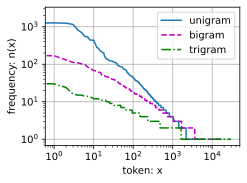

In [16]:
bigram_freqs = [freq for token, freq in bigram_vocab.token_freqs]
trigram_freqs = [freq for token, freq in trigram_vocab.token_freqs]
d2l.plot([freqs, bigram_freqs, trigram_freqs], xlabel='token: x',
         ylabel='frequency: n(x)', xscale='log', yscale='log',
         legend=['unigram', 'bigram', 'trigram'])

- 总结：随着组合长度增加，我们可以观察到更多上下文信息

## 8.3.4.1. 随机采样

In [17]:
# 参数batch_size指定了每个小批量中子序列样本的数目，
# 参数num_steps是每个子序列中预定义的时间步数。也就是有多少个数字
def seq_data_iter_random(corpus, batch_size, num_steps):  #@save
    """使用随机抽样生成一个小批量子序列"""
    # 从随机偏移量开始对序列进行分区，随机范围包括num_steps-1
    # 为了让每次采样的起点有所变化，避免每次都从序列的第一个位置开始划分。
    corpus = corpus[random.randint(0, num_steps - 1):]
    # 减去1，是因为我们需要考虑标签
    num_subseqs = (len(corpus) - 1) // num_steps
    # 长度为num_steps的子序列的起始索引
    initial_indices = list(range(0, num_subseqs * num_steps, num_steps))
    # 在随机抽样的迭代过程中，
    # 来自两个相邻的、随机的、小批量中的子序列不一定在原始序列上相邻
    random.shuffle(initial_indices)
    # 打乱子序列的起始索引

    def data(pos):
        # 返回从pos位置开始的长度为num_steps的序列
        return corpus[pos: pos + num_steps]

    num_batches = num_subseqs // batch_size
    for i in range(0, batch_size * num_batches, batch_size):
        # 在这里，initial_indices包含子序列的随机起始索引
        initial_indices_per_batch = initial_indices[i: i + batch_size]
        X = [data(j) for j in initial_indices_per_batch]
        Y = [data(j + 1) for j in initial_indices_per_batch]
        yield torch.tensor(X), torch.tensor(Y)

- `random.randint(0,num_steps -1)`:随机范围里的生成一个整数
- `yield`：返回当前批次的数据，但保留函数的执行状态，下次迭代时接着往下执行

In [18]:
my_seq = list(range(35))
for X, Y in seq_data_iter_random(my_seq, batch_size=2, num_steps=5):
    print('X: ', X, '\nY:', Y)

X:  tensor([[22, 23, 24, 25, 26],
        [12, 13, 14, 15, 16]]) 
Y: tensor([[23, 24, 25, 26, 27],
        [13, 14, 15, 16, 17]])
X:  tensor([[ 2,  3,  4,  5,  6],
        [27, 28, 29, 30, 31]]) 
Y: tensor([[ 3,  4,  5,  6,  7],
        [28, 29, 30, 31, 32]])
X:  tensor([[17, 18, 19, 20, 21],
        [ 7,  8,  9, 10, 11]]) 
Y: tensor([[18, 19, 20, 21, 22],
        [ 8,  9, 10, 11, 12]])


随机采样的特点
每条子序列内部仍然保持原始顺序，但是：
- 子序列的起点会随机偏移。
- 子序列的排列顺序会被打乱。
- 不同批次之间的子序列不保证在原始文本中连续。

## 8.3.4.2. 顺序分区

In [19]:
def seq_data_iter_sequential(corpus, batch_size, num_steps):  #@save
    """使用顺序分区生成一个小批量子序列"""
    # 从随机偏移量开始划分序列
    offset = random.randint(0, num_steps)
    # 计算能使用多少数字
    num_tokens = ((len(corpus) - offset - 1) // batch_size) * batch_size
    Xs = torch.tensor(corpus[offset: offset + num_tokens])
    Ys = torch.tensor(corpus[offset + 1: offset + 1 + num_tokens])
    Xs, Ys = Xs.reshape(batch_size, -1), Ys.reshape(batch_size, -1)
    num_batches = Xs.shape[1] // num_steps
    for i in range(0, num_steps * num_batches, num_steps):
        X = Xs[:, i: i + num_steps]
        Y = Ys[:, i: i + num_steps]
        yield X, Y

In [20]:
for X, Y in seq_data_iter_sequential(my_seq, batch_size=2, num_steps=5):
    print('X: ', X, '\nY:', Y)

X:  tensor([[ 1,  2,  3,  4,  5],
        [17, 18, 19, 20, 21]]) 
Y: tensor([[ 2,  3,  4,  5,  6],
        [18, 19, 20, 21, 22]])
X:  tensor([[ 6,  7,  8,  9, 10],
        [22, 23, 24, 25, 26]]) 
Y: tensor([[ 7,  8,  9, 10, 11],
        [23, 24, 25, 26, 27]])
X:  tensor([[11, 12, 13, 14, 15],
        [27, 28, 29, 30, 31]]) 
Y: tensor([[12, 13, 14, 15, 16],
        [28, 29, 30, 31, 32]])


In [31]:
class SeqDataLoader:  #@save
    """加载序列数据的迭代器"""
    def __init__(self, batch_size, num_steps, use_random_iter, max_tokens):
        if use_random_iter:
            self.data_iter_fn = seq_data_iter_random
        else:
            self.data_iter_fn = seq_data_iter_sequential
        self.corpus, self.vocab = load_corpus_time_machine(max_tokens)
        self.batch_size, self.num_steps = batch_size, num_steps

    def __iter__(self):
        return self.data_iter_fn(self.corpus, self.batch_size, self.num_steps)

In [22]:
def load_data_time_machine(batch_size, num_steps,  #@save
                           use_random_iter=False, max_tokens=10000):
    """返回时光机器数据集的迭代器和词表"""
    data_iter = SeqDataLoader(
        batch_size, num_steps, use_random_iter, max_tokens)
    return data_iter, data_iter.vocab

# 8.5. 循环神经网络的从零开始实现

In [32]:
%matplotlib inline
import math
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

batch_size, num_steps = 32, 35
train_iter, vocab = load_data_time_machine(batch_size, num_steps)

## 8.5.1. 独热编码

In [34]:
F.one_hot(torch.tensor([0, 2]), len(vocab))

tensor([[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0]])

- 我们每次采样的小批量数据形状是二维张量： （批量大小，时间步数）。
-  one_hot函数将这样一个小批量数据转换成三维张量， 张量的最后一个维度等于词表大小（len(vocab)）。

In [35]:
X = torch.arange(10).reshape((2, 5))
F.one_hot(X.T, 28).shape

torch.Size([5, 2, 28])

## 8.5.2. 初始化模型参数

In [ ]:
# 隐藏单元数num_hiddens是一个可调的超参数。
def get_params(vocab_size,num_hiddens,device):
    num_inputs =num_outputs = vocab_size
    # 为什么输入输出都等于vocab_size

# 下面这个是初始化的嘛，randn是随机生成，*0.01干什么，不清楚
    def normal(shape):
        return torch.randn(size = shape,device =device) * 0.01

     # 隐藏层参数
    W_xh = normal((num_inputs, num_hiddens))
    W_hh = normal((num_hiddens, num_hiddens))
    b_h = torch.zeros(num_hiddens, device=device)
    # 输出层参数
    W_hq = normal((num_hiddens, num_outputs))
    b_q = torch.zeros(num_outputs, device=device)
     # 附加梯度
    params = [W_xh, W_hh, b_h, W_hq, b_q]
    for param in params:
        param.requires_grad_(True)
    return params


    

## 8.5.3. 循环神经网络模型

In [ ]:
def init_rnn_state(batch_size, num_hiddens, device):
    return (torch.zeros((batch_size, num_hiddens), device=device), )
    # 为什么是这个形状的

In [ ]:
def rnn(inputs,state,params):
    # inputs的形状：(时间步数量，批量大小，词表大小)
    W_xh, W_hh, b_h, W_hq, b_q = params
    H, = state # 为什么会有一个逗号，这是什么语法
    outputs = []
     # X的形状：(批量大小，词表大小)
    for X in inputs:
        # 后面这俩就是纯公式
        H = torch.tanh(torch.mm(X, W_xh) + torch.mm(H, W_hh) + b_h)
        Y= torch.mm(H, W_hq) + b_q
        outputs.append(Y)
    return torch.cat(outputs, dim=0), (H,) # 输出+当前隐藏状态
# cat的用法是：
# outputs应该是一个列表，那么cat是怎么作用的

In [38]:
class RNNModelScratch: #@save
    """从零开始实现的循环神经网络模型"""
    def __init__(self, vocab_size, num_hiddens, device,
                 get_params, init_state, forward_fn):
        self.vocab_size, self.num_hiddens = vocab_size, num_hiddens
        self.params = get_params(vocab_size, num_hiddens, device)
        self.init_state, self.forward_fn = init_state, forward_fn

    def __call__(self, X, state):
        X = F.one_hot(X.T, self.vocab_size).type(torch.float32)
        return self.forward_fn(X, state, self.params)

    def begin_state(self, batch_size, device):
        return self.init_state(batch_size, self.num_hiddens, device)

In [43]:
num_hiddens = 512
net = RNNModelScratch(len(vocab), num_hiddens, d2l.try_gpu(), get_params,
                      init_rnn_state, rnn)
state = net.begin_state(X.shape[0], d2l.try_gpu())
Y, new_state = net(X.to(d2l.try_gpu()), state)
Y.shape, len(new_state), new_state[0].shape

(torch.Size([10, 28]), 1, torch.Size([2, 512]))

## 8.5.4. 预测

In [ ]:
def predict_ch8(prefix, num_preds, net, vocab, device):  #@save
    """在prefix后面生成新字符"""
    state = net.begin_state(batch_size=1, device=device)
    outputs = [vocab[prefix[0]]] # 什么意思。存的是下标吧，一开始只有第一个字符的下标
    get_input = lambda: torch.tensor([outputs[-1]], device=device).reshape((1, 1))
    # outputs[-1]，刚预测完的那个词的下表
    # 我去，下面这段代码什么意思
    for y in prefix[1:]:  # 预热期
        _, state = net(get_input(), state)
        outputs.append(vocab[y])
    # 下面这一段也没看懂
    for _ in range(num_preds):  # 预测num_preds步
        y, state = net(get_input(), state)
        outputs.append(int(y.argmax(dim=1).reshape(1)))
    return ''.join([vocab.idx_to_token[i] for i in outputs])
    # join是什么语法,哦哦哦，我猜一下，就是把那个token都加到''里面是吗，个个紧挨着

- `num_preds`:想要生成多少个词

In [45]:
predict_ch8('time traveller ', 10, net, vocab, d2l.try_gpu())

'time traveller hgeebuclts'

## 8.5.5. 梯度裁剪

In [ ]:
def grad_clipping(net, theta):  #@save
    """裁剪梯度"""
    if isinstance(net, nn.Module):
        params = [p for p in net.parameters() if p.requires_grad]
    else:
        params = net.params# 所有层的参数都放在一起
    norm = torch.sqrt(sum(torch.sum((p.grad ** 2)) for p in params))
    # 这个norm两个sum是什么意思
    if norm > theta:
        for param in params:
            param.grad[:] *= theta / norm

## 8.5.6. 训练

In [47]:
#@save
def train_epoch_ch8(net, train_iter, loss, updater, device, use_random_iter):
    """训练网络一个迭代周期（定义见第8章）"""
    state, timer = None, d2l.Timer()
    metric = d2l.Accumulator(2)  # 训练损失之和,词元数量
    for X, Y in train_iter:
        if state is None or use_random_iter:
            # 在第一次迭代或使用随机抽样时初始化state
            state = net.begin_state(batch_size=X.shape[0], device=device)
        else:
            if isinstance(net, nn.Module) and not isinstance(state, tuple):
                # state对于nn.GRU是个张量
                state.detach_()
            else:
                # state对于nn.LSTM或对于我们从零开始实现的模型是个张量
                for s in state:
                    s.detach_()
        y = Y.T.reshape(-1)
        X, y = X.to(device), y.to(device)
        y_hat, state = net(X, state)
        l = loss(y_hat, y.long()).mean()
        if isinstance(updater, torch.optim.Optimizer):
            updater.zero_grad()
            l.backward()
            grad_clipping(net, 1)
            updater.step()
        else:
            l.backward()
            grad_clipping(net, 1)
            # 因为已经调用了mean函数
            updater(batch_size=1)
        metric.add(l * y.numel(), y.numel())
    return math.exp(metric[0] / metric[1]), metric[1] / timer.stop()

- 这一部分就注意一下use_random_iter，如果为true，就得每次都更新状态，否则之前的状态接着用

In [48]:
#@save
def train_ch8(net, train_iter, vocab, lr, num_epochs, device,
              use_random_iter=False):
    """训练模型（定义见第8章）"""
    loss = nn.CrossEntropyLoss()
    animator = d2l.Animator(xlabel='epoch', ylabel='perplexity',
                            legend=['train'], xlim=[10, num_epochs])
    # 初始化
    if isinstance(net, nn.Module):
        updater = torch.optim.SGD(net.parameters(), lr)
    else:
        updater = lambda batch_size: d2l.sgd(net.params, lr, batch_size)
    predict = lambda prefix: predict_ch8(prefix, 50, net, vocab, device)
    # 训练和预测
    for epoch in range(num_epochs):
        ppl, speed = train_epoch_ch8(
            net, train_iter, loss, updater, device, use_random_iter)
        if (epoch + 1) % 10 == 0:
            print(predict('time traveller'))
            animator.add(epoch + 1, [ppl])
    print(f'困惑度 {ppl:.1f}, {speed:.1f} 词元/秒 {str(device)}')
    print(predict('time traveller'))
    print(predict('traveller'))

困惑度 1.1, 82767.1 词元/秒 cuda:0
time traveller for so it will be convenient to speak of himwas e
traveller with a slight accession ofcheerfulness really thi


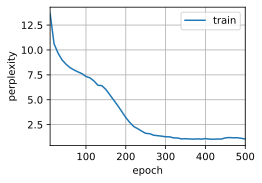

In [49]:
num_epochs, lr = 500, 1
train_ch8(net, train_iter, vocab, lr, num_epochs, d2l.try_gpu())

困惑度 1.5, 80521.3 词元/秒 cuda:0
time travellerit s against reason said filby of course a solid b
travellerit s against reason said filby of course a solid b


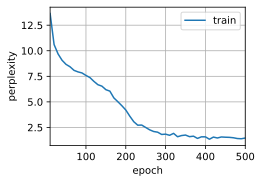

In [50]:
net = RNNModelScratch(len(vocab), num_hiddens, d2l.try_gpu(), get_params,
                      init_rnn_state, rnn)
train_ch8(net, train_iter, vocab, lr, num_epochs, d2l.try_gpu(),
          use_random_iter=True)

- 需要你帮忙分析一下两个结果。